<a href="https://colab.research.google.com/github/dawitwo/ML-For-Beginners/blob/main/Amharic%20Audio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
audio_path = '/content/drive/MyDrive/Amharic Audio/'

In [16]:
# List the contents of the audio directory to find the correct file name
import os
print(f"Contents of {audio_path}:")
for item in os.listdir(audio_path):
    print(item)


Contents of /content/drive/MyDrive/Amharic Audio/:
.DS_Store
amh-spk-10-M
amh-spk-12-M
amh-spk-1-M
amh-spk-4-M
amh-spk-11-M
amh-spk-2-F
amh-spk-5-F
amh-spk-3-F
amh-spk-7-F
amh-spk-6-M
amh-spk-8-F
amh-spk-9-F


In [8]:
pip install librosa matplotlib

In [18]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os

# Construct the full path to your audio file
# IMPORTANT: Replace 'your_audio_file.wav' with the actual name of your audio file
audio_file_name = '/content/drive/MyDrive/Amharic Audio/amh-spk-1-M/230104-143048_amh_8bc_elicit/230104-143048_amh_8bc_elicit_0.wav' # <--- USER EDIT REQUIRED HERE
full_audio_path = os.path.join(audio_path, audio_file_name)

print(f"Attempting to load audio from: {full_audio_path}")

# Load the audio file
try:
    y, sr = librosa.load(full_audio_path, sr=None) # sr=None to preserve original sampling rate
    print(f"Audio loaded successfully: Sampling Rate = {sr} Hz, Duration = {len(y)/sr:.2f} seconds")
except FileNotFoundError:
    print(f"Error: Audio file not found at {full_audio_path}")
    y, sr = None, None # Set to None to prevent further errors
except Exception as e:
    print(f"An error occurred while loading the audio file: {e}")
    y, sr = None, None


Attempting to load audio from: /content/drive/MyDrive/Amharic Audio/amh-spk-1-M/230104-143048_amh_8bc_elicit/230104-143048_amh_8bc_elicit_0.wav
Audio loaded successfully: Sampling Rate = 16000 Hz, Duration = 7.03 seconds


In [17]:
# List the contents of the 'amh-spk-1-M' directory to find an actual audio file
import os
subdirectory_path = os.path.join(audio_path, 'amh-spk-1-M')
print(f"Contents of {subdirectory_path}:")
if os.path.isdir(subdirectory_path):
    for item in os.listdir(subdirectory_path):
        print(item)
else:
    print(f"Error: {subdirectory_path} is not a directory.")


Contents of /content/drive/MyDrive/Amharic Audio/amh-spk-1-M:
.DS_Store
230104-153448_amh_8bc_elicit
230104-143048_amh_8bc_elicit


In [13]:
# List the contents of the audio directory to find the correct file name
import os
print(f"Contents of {audio_path}:")
for item in os.listdir(audio_path):
    print(item)


Contents of /content/drive/MyDrive/Amharic Audio/:
.DS_Store
amh-spk-10-M
amh-spk-12-M
amh-spk-1-M
amh-spk-4-M
amh-spk-11-M
amh-spk-2-F
amh-spk-5-F
amh-spk-3-F
amh-spk-7-F
amh-spk-6-M
amh-spk-8-F
amh-spk-9-F


In [14]:
# List the contents of the audio directory to find the correct file name
import os
print(f"Contents of {audio_path}:")
for item in os.listdir(audio_path):
    print(item)


Contents of /content/drive/MyDrive/Amharic Audio/:
.DS_Store
amh-spk-10-M
amh-spk-12-M
amh-spk-1-M
amh-spk-4-M
amh-spk-11-M
amh-spk-2-F
amh-spk-5-F
amh-spk-3-F
amh-spk-7-F
amh-spk-6-M
amh-spk-8-F
amh-spk-9-F


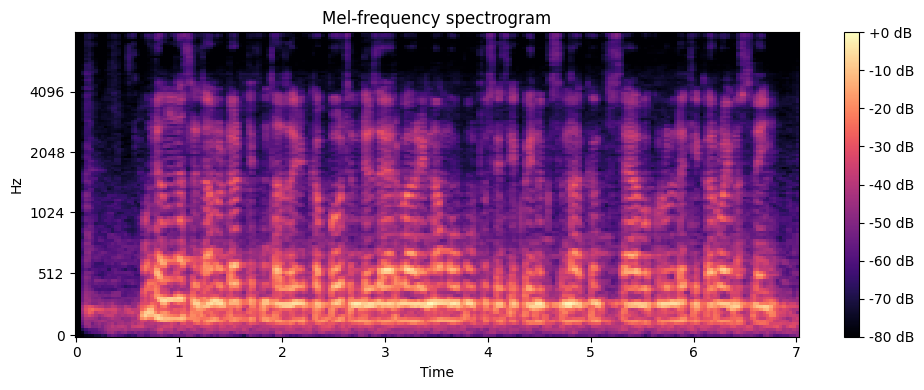

Spectrogram saved to: /content/drive/MyDrive/Amharic Audio/amh-spk-1-M/230104-143048_amh_8bc_elicit/230104-143048_amh_8bc_elicit_0_spectrogram.png


<Figure size 640x480 with 0 Axes>

In [20]:
import numpy as np

if y is not None and sr is not None:
    # Generate a Mel-frequency spectrogram
    # Using n_fft=2048 and hop_length=512 are common choices
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=2048, hop_length=512)

    # Convert to log scale (decibels) for better visualization
    S_db = librosa.power_to_db(S, ref=np.max(S))

    # Display the spectrogram
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel')
    plt.colorbar(format='%+2.0f dB')
    plt.title('Mel-frequency spectrogram')
    plt.tight_layout()
    plt.show()

    # Save the spectrogram as an image file
    output_image_path = os.path.join(audio_path, f'{os.path.splitext(audio_file_name)[0]}_spectrogram.png')
    plt.savefig(output_image_path)
    print(f"Spectrogram saved to: {output_image_path}")
else:
    print("Cannot generate spectrogram: audio data was not loaded successfully.")

### Processing all Audio Files and Generating Spectrograms

Now, let's extend this to find all `.wav` files within your `audio_path` and generate a spectrogram for each. We'll save these in a dedicated output directory.

In [21]:
import os

# Define output directories
SPECTROGRAMS_OUTPUT_DIR = os.path.join(audio_path, 'Spectrograms')
PADDED_SPECTROGRAMS_OUTPUT_DIR = os.path.join(audio_path, 'Padded_Spectrograms')

os.makedirs(SPECTROGRAMS_OUTPUT_DIR, exist_ok=True)
os.makedirs(PADDED_SPECTROGRAMS_OUTPUT_DIR, exist_ok=True)

print(f"Spectrograms will be saved to: {SPECTROGRAMS_OUTPUT_DIR}")
print(f"Padded Spectrograms will be saved to: {PADDED_SPECTROGRAMS_OUTPUT_DIR}")

# Collect all .wav files
audio_files_to_process = []
for root, _, files in os.walk(audio_path):
    for file in files:
        if file.endswith('.wav'):
            audio_files_to_process.append(os.path.join(root, file))

print(f"Found {len(audio_files_to_process)} WAV files to process.")

# This list will store paths to all generated spectrogram images
generated_spectrogram_paths = []

Spectrograms will be saved to: /content/drive/MyDrive/Amharic Audio/Spectrograms
Padded Spectrograms will be saved to: /content/drive/MyDrive/Amharic Audio/Padded_Spectrograms
Found 1567 WAV files to process.


In [22]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import os

for i, full_audio_path in enumerate(audio_files_to_process):
    print(f"[{i+1}/{len(audio_files_to_process)}] Processing: {full_audio_path}")

    # Load the audio file
    try:
        y, sr = librosa.load(full_audio_path, sr=None) # sr=None to preserve original sampling rate
    except Exception as e:
        print(f"  Error loading {full_audio_path}: {e}")
        continue

    # Generate Mel-frequency spectrogram
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=2048, hop_length=512)
    S_db = librosa.power_to_db(S, ref=np.max(S))

    # Display and save the spectrogram
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'Mel-frequency spectrogram for {os.path.basename(full_audio_path)}')
    plt.tight_layout()

    # Create a unique filename for the spectrogram
    # Use relative path to create a nested structure in the output if desired,
    # or just use a flattened structure with unique names.
    relative_path = os.path.relpath(full_audio_path, audio_path)
    spectrogram_filename = os.path.splitext(relative_path)[0].replace(os.path.sep, '_') + '.png'
    output_image_path = os.path.join(SPECTROGRAMS_OUTPUT_DIR, spectrogram_filename)

    plt.savefig(output_image_path)
    plt.close() # Close the plot to free up memory

    generated_spectrogram_paths.append(output_image_path)

print(f"Successfully generated {len(generated_spectrogram_paths)} spectrograms.")

[1/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_69.wav
[2/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_85.wav
[3/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_17.wav
[4/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_15.wav
[5/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_31.wav
[6/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_81.wav
[7/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_46.wav
[8/1567] Processing: /content/drive/MyDrive/Amha

/tmp/ipykernel_1718/367133508.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(full_audio_path, sr=None) # sr=None to preserve original sampling rate
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


[48/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_1.wav
[49/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_80.wav
[50/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_14.wav
[51/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_32.wav
[52/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_56.wav
[53/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_78.wav
[54/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_84.wav
[55/1567] Processing: /content/drive/MyDri

/tmp/ipykernel_1718/367133508.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(full_audio_path, sr=None) # sr=None to preserve original sampling rate
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


[87/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_75.wav
[88/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-190351_amh_3d1_elicit/230103-190351_amh_3d1_elicit_73.wav
[89/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-200131_amh_3d1_elicit/230103-200131_amh_3d1_elicit_126.wav
[90/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-200131_amh_3d1_elicit/230103-200131_amh_3d1_elicit_98.wav
[91/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-200131_amh_3d1_elicit/230103-200131_amh_3d1_elicit_125.wav
[92/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-200131_amh_3d1_elicit/230103-200131_amh_3d1_elicit_127.wav
[93/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-10-M/230103-200131_amh_3d1_elicit/230103-200131_amh_3d1_elicit_120.wav
[94/1567] Processing: /content/drive/

...

  Error loading /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_33.wav: 
[1475/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_27.wav
[1476/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_120.wav
[1477/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_118.wav
[1478/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_127.wav
[1479/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_3.wav
[1480/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_32.wav
[1481/1567] Processing: /content/drive

/tmp/ipykernel_1718/367133508.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(full_audio_path, sr=None) # sr=None to preserve original sampling rate
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


  Error loading /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_78.wav: 
[1526/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_102.wav
[1527/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_5.wav
[1528/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_51.wav
[1529/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_44.wav
[1530/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_46.wav
[1531/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_116.wav
[1532/1567] Processing: /content/drive/

/tmp/ipykernel_1718/367133508.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(full_audio_path, sr=None) # sr=None to preserve original sampling rate
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


  Error loading /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_80.wav: 
[1544/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_68.wav
[1545/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_40.wav
[1546/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_79.wav
[1547/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_82.wav
[1548/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_96.wav
[1549/1567] Processing: /content/drive/MyDrive/Amharic Audio/amh-spk-9-F/230103-090619_amh_3d1_elicit/230103-090619_amh_3d1_elicit_81.wav
[1550/1567] Processing: /content/drive/M

### Standardizing Spectrogram Image Sizes (Padding)

Now that we have all spectrograms generated, let's load them, find the maximum dimensions, and then pad each image to ensure they all have the same size. This is useful for consistent input to machine learning models.

In [23]:
from PIL import Image
import os

if not generated_spectrogram_paths:
    print("No spectrograms were generated to pad.")
else:
    max_width = 0
    max_height = 0

    # First pass: Find the maximum width and height among all spectrograms
    print("Determining maximum dimensions for padding...")
    for img_path in generated_spectrogram_paths:
        try:
            with Image.open(img_path) as img:
                width, height = img.size
                if width > max_width:
                    max_width = width
                if height > max_height:
                    max_height = height
        except Exception as e:
            print(f"  Error opening image {img_path}: {e}")

    print(f"Maximum dimensions found: Width = {max_width}, Height = {max_height}")

    # Second pass: Pad each image to max_width and max_height
    print("Padding spectrograms...")
    padded_spectrogram_count = 0
    for img_path in generated_spectrogram_paths:
        try:
            with Image.open(img_path) as img:
                # Create a new image with the maximum dimensions and a black background
                padded_img = Image.new('RGB', (max_width, max_height), color='black')

                # Paste the original image onto the center of the new image
                # Calculate coordinates to paste at top-left corner, or center if desired
                x_offset = 0 # (max_width - img.width) // 2 for centering
                y_offset = 0 # (max_height - img.height) // 2 for centering
                padded_img.paste(img, (x_offset, y_offset))

                # Save the padded image to the new directory
                padded_filename = os.path.basename(img_path)
                padded_output_path = os.path.join(PADDED_SPECTROGRAMS_OUTPUT_DIR, padded_filename)
                padded_img.save(padded_output_path)
                padded_spectrogram_count += 1
        except Exception as e:
            print(f"  Error padding image {img_path}: {e}")

    print(f"Successfully padded and saved {padded_spectrogram_count} spectrograms to {PADDED_SPECTROGRAMS_OUTPUT_DIR}.")

Determining maximum dimensions for padding...
Maximum dimensions found: Width = 1000, Height = 400
Padding spectrograms...
Successfully padded and saved 1540 spectrograms to /content/drive/MyDrive/Amharic Audio/Padded_Spectrograms.


In [27]:
!git add



fatal: not a git repository (or any of the parent directories): .git
